In [1]:
### Step 1-1: Install libraries
!pip install evaluate==0.4.4       # Install evaluate library.
!pip install datasets              # Install datasets library from HuggingFace.
!pip install -U datasets huggingface_hub fsspec
!pip install transformers==4.45.2  # Install transformers for model inference.
!pip install rouge_score           # Install ROUGE metric.
!pip install scikit-learn          # Install sklearn for classification metrics.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.0/527.0 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 618.0/618.0 kB 47.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 202.5/202.5 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 18.7 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.0
    Uninstalling fsspec-2025.3.0:
      Successfully uninstalled fsspec-2025.3.0
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.7.1
    Uninstalling huggingface_hub-1.7.1:
      Successfully uninstalled huggingface_hub-1.7.1
  Attempting uninstall: datasets
    Found existing installation: datasets 4.0.0
    Uninsta

In [2]:
### Step 1-2: Import libraries and set environment

import os  # operating system interface.
os.environ['WANDB_DISABLED'] = 'true'
os.environ['TOKENIZERS_PARALLELISM'] = 'true'  # enable HF tokenizer parallelism
import gc
import torch
import numpy as np
import matplotlib.pyplot as plt
from functools import partial  # create pre-filled function arguments.

from datasets import load_dataset  # load benchmark datasets from HF.
from transformers import (
    GPT2Tokenizer,                    # load pretrained GPT2 tokenizer
    GPT2ForSequenceClassification,    # load pretrained model for sequence classification
    Trainer,                          # HF Trainer for training and evaluation
    TrainingArguments,                # set training parameters
    AutoTokenizer,
    AutoModelForSeq2SeqLM,            # load pretrained seq2seq model
    Seq2SeqTrainingArguments,         # set seq2seq training parameters
    Seq2SeqTrainer,                   # HF Trainer for seq2seq models
    DataCollatorForSeq2Seq,           # dynamic padding for seq2seq training
)
from sklearn.metrics import accuracy_score, precision_score, f1_score  # evaluation metrics for classification
import evaluate


In [3]:
### Step 1-3: Define shared helper function for dataset sampling

def select_test_subset(dataset, n=None, mode='head', seed=42):
    if n is None:
        return dataset

    n = min(n, len(dataset))

    if mode == 'all':    # mode == 'all' means dont sampling
        return dataset

    elif mode == 'head': # mode == 'head' means sequential samples from the beginning
        return dataset.select(range(n))

    elif mode == 'random': # mode == 'random' means random samples from the dataset
        return dataset.shuffle(seed=seed).select(range(n))

    else:
        raise ValueError("mode must be 'all', 'head' or 'random'")


In [4]:
### Step 1-4: Define preprocessing and evaluation functions

### Preprocessing function for summarisation
def preprocess_function(examples, tokenizer=None):
    prefix = 'summarize: '
    inputs = [prefix + doc for doc in examples['article']]  # CNN/DailyMail uses 'article' field
    # cap max_length at 1024 to avoid OverflowError (BART stores model_max_length as a very large number)
    safe_max_len = 1024
    model_inputs = tokenizer(inputs, max_length=safe_max_len, truncation=True)  # truncation to fit model's maximum input length.
    labels = tokenizer(text_target=examples['highlights'], max_length=128, truncation=True)  # CNN/DailyMail uses 'highlights' field
    model_inputs['labels'] = labels['input_ids']
    return model_inputs


### Define the evaluation metrics for summarisation
def compute_metrics_summarisation(eval_pred, tokenizer=None):
    rouge = evaluate.load('rouge')
    predictions, labels = eval_pred

    predictions = np.where(predictions != -100, predictions, tokenizer.pad_token_id)  # proper decoding of predictions.
    decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)  # decode predicted tokens, remove special tokens.
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)  # decode reference summaries.
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    rouge_result = rouge.compute(predictions=decoded_preds, references=decoded_labels, use_stemmer=True)  # compute ROUGE scores.
    prediction_lens = [np.count_nonzero(pred != tokenizer.pad_token_id) for pred in predictions]  # length of each prediction.
    rouge_result['gen_len'] = np.mean(prediction_lens)  # average length of generated summaries

    bleu_metric = evaluate.load('bleu')
    # compute bleu score
    try:
        bleu_1_score = bleu_metric.compute(predictions=decoded_preds, references=decoded_labels, max_order=1)['bleu']
    except:
        bleu_1_score = 0
    try:
        bleu_2_score = bleu_metric.compute(predictions=decoded_preds, references=decoded_labels, max_order=2)['bleu']
    except:
        bleu_2_score = 0
    try:
        bleu_3_score = bleu_metric.compute(predictions=decoded_preds, references=decoded_labels, max_order=3)['bleu']
    except:
        bleu_3_score = 0
    try:
        bleu_4_score = bleu_metric.compute(predictions=decoded_preds, references=decoded_labels, max_order=4)['bleu']
    except:
        bleu_4_score = 0

    outputs = {k: round(v, 4) for k, v in rouge_result.items()}
    outputs.update({
        'bleu-1': bleu_1_score,
        'bleu-2': bleu_2_score,
        'bleu-3': bleu_3_score,
        'bleu-4': bleu_4_score,
    })
    print('ROUGE scores: ')
    print(f'Rouge 1: {outputs["rouge1"]:.4f}')
    print(f'Rouge 2: {outputs["rouge2"]:.4f}')
    print(f'Rouge L: {outputs["rougeL"]:.4f}')
    print(f'Rouge Lsum: {outputs["rougeLsum"]:.4f}')
    print('BLEU scores: ')
    print(f'BLEU-1: {outputs["bleu-1"]:.4f}')
    print(f'BLEU-2: {outputs["bleu-2"]:.4f}')
    print(f'BLEU-3: {outputs["bleu-3"]:.4f}')
    print(f'BLEU-4: {outputs["bleu-4"]:.4f}')
    return outputs


In [5]:
## Create a function called Classify_Yelp_Reviews that packages all required
## dataset, model settings, training parameters, and the training pipeline into one function.

def Classify_Yelp_Reviews():
    # Step 1-1: Load the dataset
    dataset = load_dataset('Yelp/yelp_review_full')  # load Yelp Review Full from HF.

    # get a subset of train dataset
    dataset['train'] = dataset['train'].select(range(500))  # Select 500 examples for demonstration
    # get a subset of test dataset
    dataset['test'] = dataset['test'].select(range(200))    # Select 200 examples for demonstration
    ## Practise: sampling test data from the standard test dataset
    # dataset['test'] = select_test_subset(dataset['test'], n=200, mode='random', seed=42)
    # the example above is sampling from datasets, 'n' represent the number of samples

    # Step 1-2: Load the GPT-2 tokenizer and model for sequence classification
    tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
    tokenizer.pad_token = tokenizer.eos_token  # Use the end-of-text token for padding

    # Tokenize the dataset
    def tokenize_function(examples):
        return tokenizer(examples['text'], padding='max_length', truncation=True, max_length=64)

    # Apply tokenization to the dataset
    tokenized_datasets = dataset.map(tokenize_function, batched=True)
    tokenized_datasets.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
    print(tokenized_datasets)

    # Split the dataset into train and test sets
    train_dataset = tokenized_datasets['train']
    test_dataset  = tokenized_datasets['test']

    # Step 2-1: Load GPT-2 for 5-class classification (num_labels=5 for Yelp 1-5 stars)
    model = GPT2ForSequenceClassification.from_pretrained(
        'gpt2',
        num_labels=5  # Yelp has 5 star rating classes
    )  ## practise: load different GPT2 family model like 'openai-community/gpt2-medium'. How does the choice of model affect performance?
    # Use last token id as pad id
    model.config.pad_token_id = model.config.eos_token_id

    # Step 2-2: Define compute metrics function for evaluation
    def compute_metrics(p):
        preds = p.predictions.argmax(axis=-1)  # Get predicted labels
        labels = p.label_ids  # True labels
        results = {
            'accuracy':  accuracy_score(labels, preds),
            'precision': precision_score(labels, preds, average='weighted', zero_division=0),
            'f1':        f1_score(labels, preds, average='weighted', zero_division=0)
        }
        return results

    print('start training')
    # Step 3-1: Training set up
    training_args = TrainingArguments(
        output_dir='./results',
        eval_strategy='epoch',          # evaluate the model to monitor performance on the validation set
        logging_strategy='epoch',       # log metrics once per epoch
        save_strategy='no',             # do not save checkpoint to avoid confusion when re-running
        learning_rate=5e-5,             # learning rate for the optimizer  ## practise: how does the learning rate affect training performance?
        per_device_train_batch_size=4,  # training batch size  ## practise: what is the relationship between batch size and sample size?
        per_device_eval_batch_size=4,
        num_train_epochs=3,             # train the model for 3 epochs  ## practise: try more epochs
        weight_decay=0.01,              # regularize the model and prevent overfitting
        report_to='none'                # disable logging reports
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=test_dataset,
        compute_metrics=compute_metrics,
    )

    # create a dictionary to store training and evaluation metrics
    result_dict = {
        'train_loss':     [],
        'eval_loss':      [],
        'eval_accuracy':  [],
        'eval_precision': [],
        'eval_f1':        [],
    }

    # rows for tabular output: baseline + training results
    table_rows = []

    # Step 3-2: Evaluate the model before training (baseline)
    before_eval_output = trainer.evaluate()
    print(f'Initial evaluation metrics accuracy: {before_eval_output["eval_accuracy"]}, '
          f'precision: {before_eval_output["eval_precision"]}, '
          f'f1: {before_eval_output["eval_f1"]}, '
          f'loss: {before_eval_output["eval_loss"]}')

    result_dict['train_loss'].append(before_eval_output['eval_loss'])
    result_dict['eval_loss'].append(before_eval_output['eval_loss'])
    result_dict['eval_accuracy'].append(before_eval_output['eval_accuracy'])
    result_dict['eval_precision'].append(before_eval_output['eval_precision'])
    result_dict['eval_f1'].append(before_eval_output['eval_f1'])

    table_rows.append({
        'step':       0,
        'train_loss': None,
        'eval_loss':  before_eval_output['eval_loss'],
        'accuracy':   before_eval_output['eval_accuracy'],
        'precision':  before_eval_output['eval_precision'],
        'f1':         before_eval_output['eval_f1'],
    })

    # Step 3-3: Training loop
    train_output = trainer.train()

    # Read per-epoch logs recorded by Trainer
    log_history = trainer.state.log_history

    current_train_loss = None
    for log in log_history:
        # training loss log
        if 'loss' in log and 'eval_loss' not in log:
            current_train_loss = log['loss']

        # evaluation log at the end of each epoch
        if 'eval_loss' in log:
            epoch_num = int(log.get('epoch', 0))
            step_num  = int(log.get('step', 0))

            print(
                f'Epoch {epoch_num} metrics -> accuracy: {log["eval_accuracy"]}, '
                f'precision: {log["eval_precision"]}, '
                f'f1: {log["eval_f1"]}, '
                f'loss: {log["eval_loss"]}'
            )

            result_dict['train_loss'].append(current_train_loss)
            result_dict['eval_loss'].append(log['eval_loss'])
            result_dict['eval_accuracy'].append(log['eval_accuracy'])
            result_dict['eval_precision'].append(log['eval_precision'])
            result_dict['eval_f1'].append(log['eval_f1'])

            table_rows.append({
                'step':       step_num,
                'train_loss': current_train_loss,
                'eval_loss':  log['eval_loss'],
                'accuracy':   log['eval_accuracy'],
                'precision':  log['eval_precision'],
                'f1':         log['eval_f1'],
            })

    # Step 3-4: Print training performance
    table_header = f"{'Step':<12}{'Training Loss':<18}{'Validation Loss':<18}{'Accuracy':<12}{'Precision':<12}{'F1':<12}"
    print(table_header)
    for row in table_rows:
        train_loss_text = 'No log' if row['train_loss'] is None else f"{row['train_loss']:.6f}"
        print(
            f"{row['step']:<12}{train_loss_text:<18}{row['eval_loss']:<18.6f}"
            f"{row['accuracy']:<12.6f}{row['precision']:<12.6f}{row['f1']:<12.6f}"
        )

    # Step 3-5: Plot training curves
    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    epochs = range(0, len(result_dict['train_loss']))  # 0 = baseline, 1..N = training epochs
    ax.plot(epochs, result_dict['train_loss'], label='Training Loss', marker='o')
    ax.plot(epochs, result_dict['eval_loss'],  label='Validation Loss', marker='o')
    ax.set_xlabel('Epochs')
    ax.set_ylabel('Loss')

    # use different y axis for accuracy
    ax2 = ax.twinx()
    ax2.set_ylabel('Accuracy', color='tab:red')
    ax2.plot(epochs, result_dict['eval_accuracy'], label='Accuracy', marker='s', color='tab:red', linestyle='--')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    ax.legend(loc='upper right')
    ax2.legend(loc='upper left')
    plt.title('Task 1: GPT-2 Classification Training Curves — Yelp Review Full')
    plt.show()


In [6]:
### Task 2-A: Evaluate T5-small on CNN/DailyMail summarisation
### Modelled on Practical_2 Evaluate_Summarization_LLM()

def Evaluate_Summarization_T5():
    ### Step 1-3: Load Dataset and Preprocess
    cnn_dataset = load_dataset('abisee/cnn_dailymail', '3.0.0')  # load CNN/DailyMail dataset

    raw_train_subset = cnn_dataset['train']
    raw_test_subset  = cnn_dataset['test']
    ## Practise: sampling test data from the standard test dataset (as did in M1-Practical 1)
    raw_train_subset = select_test_subset(raw_train_subset, n=500, mode='random', seed=42)
    raw_test_subset  = select_test_subset(raw_test_subset,  n=200, mode='random', seed=42)
    # the example above is sampling from datasets, 'n' represent the number of samples

    # preprocess the text in the dataset
    tokenizer = AutoTokenizer.from_pretrained('t5-small')  # load the CORRESPONDING tokenizer, MUST same as your load model name!
    if tokenizer.pad_token is None:
        tokenizer.add_special_tokens({'pad_token': tokenizer.eos_token})  # T5 has no pad token by default

    # apply preprocessing to the dataset, tokenizing inputs and summaries
    tokenized_train = raw_train_subset.map(
        partial(preprocess_function, tokenizer=tokenizer),
        batched=True
    )
    tokenized_test = raw_test_subset.map(
        partial(preprocess_function, tokenizer=tokenizer),
        batched=True
    )

    # create a seq2seq data collator to pad inputs and labels within each batch
    data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model='t5-small')  ## MUST be same as your load model name!

    ## Step 2-1: Create a model and load the pretrained weights
    model = AutoModelForSeq2SeqLM.from_pretrained('t5-small')  ## Practise: change to 'google-t5/t5-base' or 'google-t5/t5-large'

    ## Step 2-2: Model Setup
    training_args = Seq2SeqTrainingArguments(
        output_dir='./results_t5/',
        eval_strategy='epoch',          # evaluate the model to monitor performance on the validation set.
        learning_rate=2e-5,             # learning rate for the optimizer.
        per_device_train_batch_size=8,  # training batch size.
        per_device_eval_batch_size=8,   # evaluation batch size.  ## Practise: reduce if out-of-memory errors occur.
        weight_decay=0.01,              # regularize the model and prevent overfitting.
        save_total_limit=3,             # limit the total number of saved checkpoints to 3.
        num_train_epochs=1,             # train the model for 1 epoch.
        generation_max_length=256,      # maximum length for generated summaries.  ## practise: can be larger or smaller?
        predict_with_generate=True,     # enable generation of predictions for evaluation.
        fp16=True,                      # faster computation and reduced memory usage on compatible GPUs.
        push_to_hub=False,              # disable pushing the model to HF after training.
        report_to='none',               # disable logging reports.
    )

    trainer = Seq2SeqTrainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_train,
        eval_dataset=tokenized_test,
        tokenizer=tokenizer,
        data_collator=data_collator,
        compute_metrics=partial(compute_metrics_summarisation, tokenizer=tokenizer),
    )

    ## Step 2-3: Evaluate the model on the test set
    print('T5-small baseline evaluation (before training):')
    trainer.evaluate(eval_dataset=tokenized_test)

    ### Step 3: Inference — evaluation summarisation performance
    text = 'summarize: ' + cnn_dataset['test'][0]['article'][:1000]
    ## you can do practise for new texts above.

    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=512).input_ids
    inputs = inputs.to(trainer.args.device)
    model  = model.to(trainer.args.device)
    outputs = model.generate(inputs, max_new_tokens=128, do_sample=False)  # generate summary with max 128 tokens.  ## practise for different token numbers.
    result = tokenizer.decode(outputs[0], skip_special_tokens=True)  # decode the generated token IDs into text.
    print('T5-small Summary: \n\n', result)
    print('\nReference Summary (highlights):\n', cnn_dataset['test'][0]['highlights'])


In [7]:
### Task 2-B: Evaluate BART-large-cnn on CNN/DailyMail summarisation
### Same structure as T5 above — compare a large fine-tuned model vs lightweight T5

def Evaluate_Summarization_BART():
    ### Step 1-3: Load Dataset and Preprocess
    cnn_dataset = load_dataset('abisee/cnn_dailymail', '3.0.0')  # load CNN/DailyMail dataset

    ## Practise: sampling test data from the standard test dataset
    raw_train_subset = select_test_subset(cnn_dataset['train'], n=500, mode='random', seed=42)
    raw_test_subset  = select_test_subset(cnn_dataset['test'],  n=200, mode='random', seed=42)

    # preprocess the text in the dataset
    tokenizer = AutoTokenizer.from_pretrained('facebook/bart-large-cnn')  # load the CORRESPONDING tokenizer, MUST same as your load model name!
    # Note: BART already has its own pad token — do not override it

    tokenized_train = raw_train_subset.map(
        partial(preprocess_function, tokenizer=tokenizer),
        batched=True
    )
    tokenized_test = raw_test_subset.map(
        partial(preprocess_function, tokenizer=tokenizer),
        batched=True
    )

    # create a seq2seq data collator to pad inputs and labels within each batch
    data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model='facebook/bart-large-cnn')  ## MUST be same as your load model name!

    ## Step 2-1: Create a model and load the pretrained weights
    model = AutoModelForSeq2SeqLM.from_pretrained('facebook/bart-large-cnn')  ## Practise: change to 'sshleifer/distilbart-cnn-12-6'

    ## Step 2-2: Model Setup
    training_args = Seq2SeqTrainingArguments(
        output_dir='./results_bart/',
        eval_strategy='epoch',          # evaluate the model to monitor performance on the validation set.
        learning_rate=2e-5,             # learning rate for the optimizer.
        per_device_train_batch_size=4,  # smaller batch size — BART is much larger than T5.  ## practise: reduce if out-of-memory.
        per_device_eval_batch_size=4,
        weight_decay=0.01,              # regularize the model and prevent overfitting.
        save_total_limit=3,             # limit the total number of saved checkpoints to 3.
        num_train_epochs=1,             # train the model for 1 epoch.
        generation_max_length=256,      # maximum length for generated summaries.  ## practise: can be larger or smaller?
        predict_with_generate=True,     # enable generation of predictions for evaluation.
        fp16=True,                      # faster computation and reduced memory usage on compatible GPUs.
        push_to_hub=False,              # disable pushing the model to HF after training.
        report_to='none',               # disable logging reports.
    )

    trainer = Seq2SeqTrainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_train,
        eval_dataset=tokenized_test,
        tokenizer=tokenizer,
        data_collator=data_collator,
        compute_metrics=partial(compute_metrics_summarisation, tokenizer=tokenizer),
    )

    ## Step 2-3: Evaluate BART on the test set (zero-shot — already fine-tuned on CNN/DailyMail)
    print('BART-large-cnn evaluation (zero-shot — already fine-tuned on CNN/DailyMail):')
    trainer.evaluate(eval_dataset=tokenized_test)

    ### Step 3: Inference — evaluation summarisation performance
    text = 'summarize: ' + cnn_dataset['test'][0]['article'][:1000]
    ## you can do practise for new texts above.

    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=1024).input_ids
    inputs = inputs.to(trainer.args.device)
    model  = model.to(trainer.args.device)
    outputs = model.generate(inputs, max_new_tokens=128, do_sample=False)  # generate summary with max 128 tokens.  ## practise for different token numbers.
    result = tokenizer.decode(outputs[0], skip_special_tokens=True)  # decode the generated token IDs into text.
    print('BART Summary: \n\n', result)
    print('\nReference Summary (highlights):\n', cnn_dataset['test'][0]['highlights'])


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

yelp_review_full/train-00000-of-00001.pa(…):   0%|          | 0.00/299M [00:00<?, ?B/s]

yelp_review_full/test-00000-of-00001.par(…):   0%|          | 0.00/23.5M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/650000 [00:00<?, ? examples/s]

...

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


start training


Initial evaluation metrics accuracy: 0.235, precision: 0.0873728813559322, f1: 0.11702898550724639, loss: 4.599310398101807


Epoch,Training Loss,Validation Loss,Model Preparation Time,Accuracy,Precision,F1
1,1.917300,1.604098,0.008000,0.310000,0.434632,0.193537
2,1.461000,1.461537,0.008000,0.345000,0.386718,0.314855
3,1.118800,1.371376,0.008000,0.430000,0.452766,0.389548


Epoch 1 metrics -> accuracy: 0.31, precision: 0.43463247863247856, f1: 0.19353723005654333, loss: 1.6040983200073242
Epoch 2 metrics -> accuracy: 0.345, precision: 0.3867179487179487, f1: 0.3148549619619001, loss: 1.4615367650985718
Epoch 3 metrics -> accuracy: 0.43, precision: 0.45276591681159895, f1: 0.3895480228193769, loss: 1.371376395225525
Step        Training Loss     Validation Loss   Accuracy    Precision   F1          
0           No log            4.599310          0.235000    0.087373    0.117029    
125         1.917300          1.604098          0.310000    0.434632    0.193537    
250         1.461000          1.461537          0.345000    0.386718    0.314855    
375         1.118800          1.371376          0.430000    0.452766    0.389548    


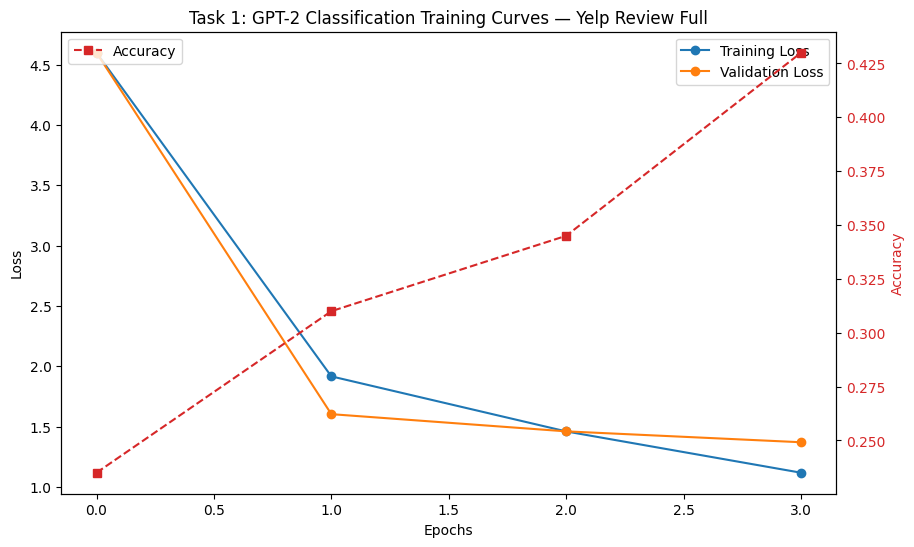

README.md: 0.00B [00:00, ?B/s]

3.0.0/train-00000-of-00003.parquet:   0%|          | 0.00/257M [00:00<?, ?B/s]

3.0.0/train-00001-of-00003.parquet:   0%|          | 0.00/257M [00:00<?, ?B/s]

3.0.0/train-00002-of-00003.parquet:   0%|          | 0.00/259M [00:00<?, ?B/s]

3.0.0/validation-00000-of-00001.parquet:   0%|          | 0.00/34.7M [00:00<?, ?B/s]

...

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

BART-large-cnn evaluation (zero-shot — already fine-tuned on CNN/DailyMail):


ROUGE scores: 
Rouge 1: 0.4287
Rouge 2: 0.1991
Rouge L: 0.2943
Rouge Lsum: 0.3628
BLEU scores: 
BLEU-1: 0.3904
BLEU-2: 0.2622
BLEU-3: 0.1935
BLEU-4: 0.1507
BART Summary: 

 The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes in Palestinian territories.

Reference Summary (highlights):
 Membership gives the ICC jurisdiction over alleged crimes committed in Palestinian territories since last June .
Israel and the United States opposed the move, which could open the door to war crimes investigations against Israelis .


In [8]:
if __name__ == '__main__':
    # Task 1: Text Classification — Yelp Review Full
    Classify_Yelp_Reviews()

    # Task 2: Text Summarisation — CNN/DailyMail
    Evaluate_Summarization_T5()
    Evaluate_Summarization_BART()
